In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import yaml
from matplotlib.lines import Line2D

ox.settings.use_cache = True
ox.settings.log_console = False

with open("plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

In [5]:
bp = gpd.read_file("../data/barriers/budapest.geojson").geometry[0]

In [7]:
selected_pings = gpd.read_file("../data/selected_pings.geojson")
selected_stops = gpd.read_file("../data/selected_stops.geojson")

In [9]:
bbox = 19.045, 47.445, 19.17, 47.505  # minX, minY, maxX, maxY
zoom = 16

In [12]:
g = ox.graph_from_bbox(bbox, simplify=False, retain_all=True)
streets = ox.graph_to_gdfs(g, nodes=False)

In [22]:
area = streets.union_all().convex_hull

duna = gpd.read_file("../data/barriers/duna.geojson")
land = gpd.GeoSeries(area.difference(duna.union_all()))

In [17]:
c_land = config["colors"]["land"]
c_street = config["colors"]["street"]
c_ping = "#874312"
c_stop = config["colors"]["darkblue"]

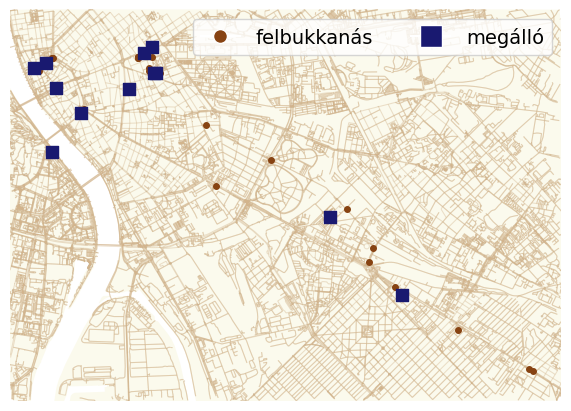

In [19]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

land.plot(color=c_land, ax=ax, zorder=1)
gpd.clip(streets, area).plot(color=c_street, linewidth=0.75, ax=ax, zorder=2)
gpd.clip(selected_pings, area).plot(
    color=c_ping, markersize=16, alpha=1, ax=ax, zorder=10
)
gpd.clip(selected_stops, area).plot(
    color=c_stop, markersize=64, marker="s", ax=ax, zorder=20
)

legend_elements = []
legend_elements.append(
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label="felbukkanás",
        markerfacecolor=c_ping,
        markersize=10,
    )
)
legend_elements.append(
    Line2D(
        [0],
        [0],
        marker="s",
        color="w",
        label="megálló",
        markerfacecolor=c_stop,
        markersize=16,
    )
)

ax.legend(
    handles=legend_elements,
    ncols=2,
    loc="upper right",
    # handletextpad=0.6,
    # columnspacing=1,
    fontsize=14,
)

ax.margins(0)
ax.axis("off")

for i in ["png"]:
    fig.savefig(
        f"../figures/pings_stops.{i}",
        dpi=150,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0,
        metadata=config["metadata"] if i != "svg" else None,
    )

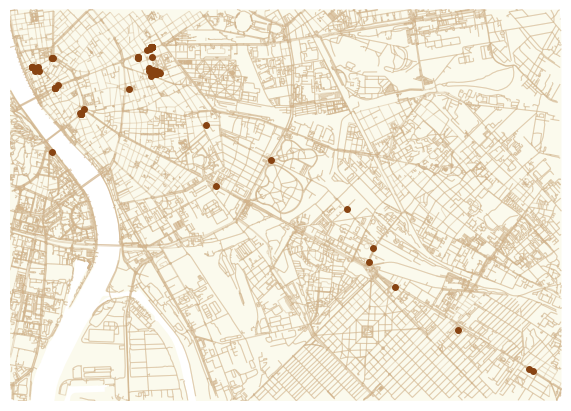

In [20]:
fig2, ax2 = plt.subplots(figsize=(6, 4), layout="constrained")

land.plot(color=c_land, ax=ax2, zorder=1)
gpd.clip(streets, area).plot(color=c_street, linewidth=0.75, ax=ax2, zorder=2)
gpd.clip(selected_pings, area).plot(
    color=c_ping, markersize=16, alpha=1, ax=ax2, zorder=10
)

ax2.margins(0)
ax2.axis("off")

for i in ["png"]:
    fig2.savefig(
        f"../figures/pings.{i}",
        dpi=150,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0,
        metadata=config["metadata"] if i != "svg" else None,
    )